In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn import metrics
import numpy as np
import altair as alt
import seaborn as sns
import matplotlib.pyplot as plt
alt.renderers.enable('notebook')
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

## From multiparametricPeptidePrediction.py

In [5]:
subset = df[["peptide_detected", "ANN_score", "gene_TPM", "NetMHC-4.0_min_affinity"]]
subset = subset.copy().rename({"NetMHC-4.0_min_affinity":"minBS",
                               "peptide_detected":"Class",
                               "gene_TPM": "mean_log_tpm"}, axis=1)
subset.mean_log_tpm = np.log(subset.mean_log_tpm)
#subset = subset[subset.minBS < 2500]
subset.head()

,Class,ANN_score,mean_log_tpm,minBS
peptide,,,,
APCNSISF,False,0.2495,-4.235491,5240.25
APHDFANI,False,0.6832,4.637337,3228.03
AIPFKSRF,False,0.4402,3.200117,12514.74
AYSCFSHL,False,0.3802,1.317207,692.33
AYSCFSHL,False,0.3802,1.317207,692.33


In [6]:
print("randomizing... how useful?")
subset = subset.sample(frac=1).reset_index(drop=True)

randomizing... how useful?


In [13]:
x_labels = ["ANN_score", "mean_log_tpm", "minBS"]
prefix = "-".join(x_labels)
print(prefix)
print("10X cross validation...")
X, y = subset[x_labels], subset.Class
clf = LogisticRegressionCV(cv=10, random_state=0, multi_class='auto',
                           class_weight={0:subset.Class.sum(), 1:subset.Class.shape[0]-subset.Class.sum()})
clf.fit(X, y)

ANN_score-mean_log_tpm-minBS
10X cross validation...


LogisticRegressionCV(Cs=10, class_weight={0: 230, 1: 536833}, cv=10, dual=False,
                     fit_intercept=True, intercept_scaling=1.0, l1_ratios=None,
                     max_iter=100, multi_class='auto', n_jobs=None,
                     penalty='l2', random_state=0, refit=True, scoring=None,
                     solver='lbfgs', tol=0.0001, verbose=0)

In [14]:
print("predictions...")
scores = clf.predict_proba(X)[:,1]
predictions = clf.predict(X)
#df["PREDICTION.RL"] = pandas.Series(predictions, index=df.index)
#df["PREDICTION.RL.PROBA"] = pandas.Series(scores, index=df.index)
print("prediction accuracy:", clf.score(X,y))
print("Regression coef %s:" % x_labels, clf.coef_)
#res_df_filename = df_filename.replace(".csv", "%s_multi_param_regression_500nm.csv" % prefix)
#print("saving regression results to %s..." % res_df_filename)
#df.to_csv(res_df_filename)

print("roc curve...")
fpr, tpr, thresholds = metrics.roc_curve(subset.Class.to_numpy(), scores)
dct =  {'FPR': fpr, 'TPR': tpr, 'THRESHOLDS': thresholds}
#df2 = pandas.DataFrame(dct)
auc = metrics.auc(fpr, tpr)
print(auc)
#print("saving curve...")
#df2.to_csv('%s_roc_500nm.csv' % prefix)

predictions...
prediction accuracy: 0.6944324967461918
Regression coef ['ANN_score', 'mean_log_tpm', 'minBS']: [[ 1.15754847e+00  5.48481770e-01 -1.59983468e-04]]
roc curve...
0.8479411174667791


In [443]:
dataset, peplen, netmhc_v = 'HumanBLCL', '9', 'NetMHC-4.0'
f = 'finalTables/{}_{}_{}.tsv.gz'.format(dataset, peplen, netmhc_v)
full_df = pd.read_csv(f, sep = '\t', index_col=0)

In [447]:
df = full_df.copy()
df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
#df = df[df['NetMHC-4.0_min_affinity'] < 1250]

In [448]:
pos_acc = sum((df.peptide_detected == True) & (df.ANN_score >= 0.5)) / sum(df.peptide_detected == True)
neg_acc = sum((df.peptide_detected == False) & (df.ANN_score < 0.5)) / sum(df.peptide_detected == False)
print(pos_acc, neg_acc)

0.46509220352870184 0.5694162152576937


In [484]:
df = full_df.copy()
#df = df[df['NetMHC-4.0_min_affinity'] < 1250]
df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
weights = abs(df.peptide_detected - (df.peptide_detected.sum() / df.peptide_detected.shape[0]))
#weights = [1]*df.peptide_detected.shape[0]
df = df.sample(n=100000, weights=weights)#, random_state=0)
df = df.rename({"NetMHC-4.0_min_affinity":"minBS", "NetMHCpan-4.0a_min_affinity":"minBS"}, axis=1)
df = df[["peptide_detected", "ANN_score", "gene_TPM", "minBS"]]
df = df.rename({"peptide_detected":"Class",
                "gene_TPM": "mean_log_tpm"}, axis=1)
df.mean_log_tpm = np.log(df.mean_log_tpm)
df.minBS = np.log(df.minBS)
print(df.Class.sum()/df.Class.shape[0])

0.46772


In [487]:
#x_labels = ['minBS']
#x_labels = ['mean_log_tpm']
#x_labels = ['ANN_score']
#x_labels = ['minBS', 'mean_log_tpm']
x_labels = ["ANN_score", "minBS"]
#x_labels = ["ANN_score", "mean_log_tpm", "minBS"]
prefix = "-".join(x_labels)
print(prefix)
print("10X cross validation...")

weights = abs(df.Class - (df.Class.sum() / df.Class.shape[0]))

X, y = df[x_labels], df.Class
clf = LogisticRegression(multi_class='auto', solver='lbfgs', random_state=0, 
                           class_weight="balanced", max_iter=100)
                           #class_weight={False:df.Class.sum(), True:df.Class.shape[0]-df.Class.sum()}, max_iter=0)
clf.fit(X, y)

print("predictions...")
scores = clf.predict_proba(X)[:,1]
predictions = clf.predict(X)
accuracy = clf.score(X,y,weights)
print("prediction accuracy:", accuracy)
print("Regression coef %s:" % x_labels, clf.coef_)
print("Regression intercept %s:" % x_labels, clf.intercept_)

print("roc curve...")
fpr, tpr, thresholds = metrics.roc_curve(df.Class.to_numpy(), scores)
dct =  {'FPR': fpr, 'TPR': tpr, 'THRESHOLDS': thresholds}
auc = metrics.auc(fpr, tpr)
print(auc)

pos_acc = sum((df.Class == True) & (predictions)) / sum(df.Class == True)
neg_acc = sum((df.Class == False) & ~(predictions)) / sum(df.Class == False)
print(pos_acc)
print(neg_acc)

ANN_score-minBS
10X cross validation...
predictions...
prediction accuracy: 0.5686941584126212
Regression coef ['ANN_score', 'minBS']: [[ 0.44393032 -0.16628694]]
Regression intercept ['ANN_score', 'minBS']: [0.72366673]
roc curve...
0.5910889459437242
0.54598905327974
0.5913992635455023


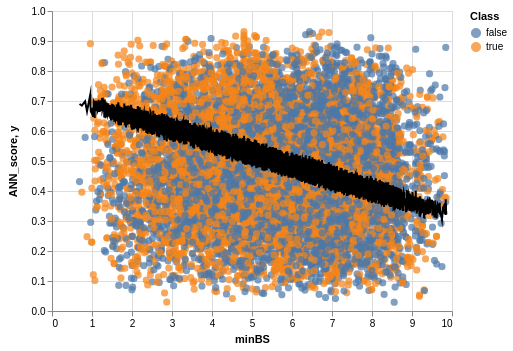

In [490]:
from scipy.special import expit
df2 = df.copy()
df2['scores'] = scores
df2['y'] = expit(np.multiply(df2[x_labels].to_numpy(), clf.coef_).sum(axis=1) + clf.intercept_).ravel()
df2 = df2.sample(n=10000, weights=weights)#, random_state=0)
chart = alt.Chart(df2).mark_circle(size=50).encode(
    x='minBS',
    y='ANN_score',
    #y='Class:Q',
    color='Class'
)

line = alt.Chart(df2).mark_line(color='black').encode(
    x='minBS',
    y='y'
)

(chart + line).interactive()

In [26]:
def apply_combination(dataset, peplen, netmhc_v, x_labels):
    f = 'finalTables/{}_{}_{}.tsv.gz'.format(dataset, peplen, netmhc_v)
    df = pd.read_csv(f, sep = '\t', index_col=0)

    # Remove non-detected peptides detected in source transcripts
    df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
    
    df = df.rename({"NetMHC-4.0_min_affinity":"minBS", "NetMHCpan-4.0a_min_affinity":"minBS"}, axis=1)
    
    df = df[["peptide_detected", "ANN_score", "gene_TPM", "minBS"]]
    df = df.rename({"peptide_detected":"Class",
                    "gene_TPM": "mean_log_tpm"}, axis=1)
    df.mean_log_tpm = np.log(df.mean_log_tpm)
    df = df[df.minBS < 500]
    #df.minBS = np.log(df.minBS)
    
    prefix = "-".join(x_labels)
    print(prefix)
    print("10X cross validation...")
    X, y = df[x_labels], df.Class
    clf = LogisticRegression(random_state=0, multi_class='auto',
                               class_weight="balanced", max_iter=1)
                               #class_weight={False:df.Class.sum(), True:df.Class.shape[0]-df.Class.sum()})
    clf.fit(X, y)
    
    print("predictions...")
    scores = clf.predict_proba(X)[:,1]
    predictions = clf.predict(X)
    accuracy = clf.score(X,y)
    print("prediction accuracy:", accuracy)
    print("Regression coef %s:" % x_labels, clf.coef_)
    
    print("roc curve...")
    fpr, tpr, thresholds = metrics.roc_curve(df.Class.to_numpy(), scores)
    dct =  {'FPR': fpr, 'TPR': tpr, 'THRESHOLDS': thresholds}
    auc = metrics.auc(fpr, tpr)
    print(auc)
    
    pos_acc = sum((df.Class == True) & (predictions)) / sum(df.Class == True)
    neg_acc = sum((df.Class == False) & ~(predictions)) / sum(df.Class == False)
    print(sum((df.Class == True) & (predictions)))
    print(pos_acc)
    print(neg_acc)
    print(df.Class.sum(), df.shape[0])
    print(predictions)
    
    global df_metrics
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'AUC', auc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'Accuracy', accuracy]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'posAcc', pos_acc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'negAcc', neg_acc]

    seen = set()
    reduced = [x for x in zip(np.round(fpr, 3), np.round(tpr, 3)) if x not in seen and not seen.add(x)]
    df_r = pd.DataFrame(reduced, columns=['fpr', 'tpr'])
    df_r['Dataset'] = dataset
    df_r['peptideLength'] = peplen
    df_r['NetMHCVersion'] = netmhc_v
    df_r['Combination'] = prefix
    
    global df_roc
    df_roc = pd.concat([df_roc, df_r], sort=False)
    
    return df[df.Class == True].ANN_score, df[df.Class == False].ANN_score

In [22]:
combinations = [
    #["ANN_score", "mean_log_tpm", "minBS"],
    #["ANN_score", "minBS"],
    #["ANN_score", "mean_log_tpm"],
    #["mean_log_tpm", "minBS"],
    ["minBS"],
    ["mean_log_tpm"],
    ["ANN_score"]
]

3 1
minBS
10X cross validation...


/u/feghalya/software/python-3.7.0/lib/python3.7/site-packages/sklearn/linear_model/logistic.py:433: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)


predictions...
prediction accuracy: 0.8418515297971729
Regression coef ['minBS']: [[-0.00074]]
roc curve...
0.5714009774476815
0
0.0
1.0
117309 741765
[False False False ... False False False]


/u/feghalya/software/python-3.7.0/lib/python3.7/site-packages/sklearn/svm/base.py:931: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  "the number of iterations.", ConvergenceWarning)


TypeError: 'AxesSubplot' object does not support indexing

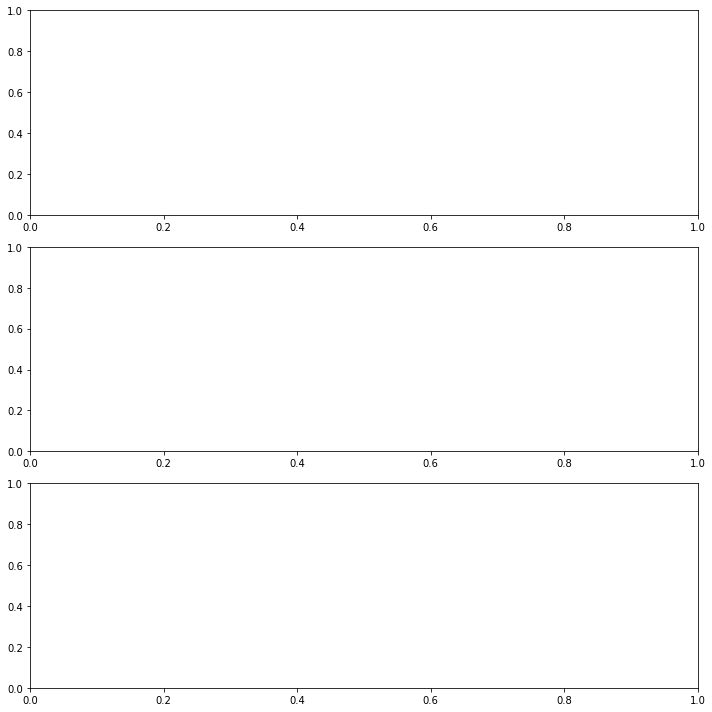

In [24]:
df_metrics = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'Combination', 'metric', 'value'])

df_roc = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'Combination', 'fpr', 'tpr'])
df_roc.loc[0] = ['diagonal', 'mid', 'line', 'plotted', 0, 0]
df_roc.loc[1] = ['diagonal', 'mid', 'line', 'plotted', 1, 1]

df_pr = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'Combination', 'precision', 'recall'])

datasets = ['HumanBLCL']
peplens = ['9']#, '9', '10', '11']
netmhc_vs = ['NetMHC-4.0']#, 'NetMHCpan-4.0a']

#fix, axs = plt.subplots(len(datasets)*len(netmhc_v), len(peplens), figsize=(10,10))
fix, axs = plt.subplots(len(datasets)*len(netmhc_vs)*len(combinations), len(peplens), figsize=(10,10))
print(len(datasets)*len(netmhc_vs)*len(combinations), len(peplens))
plt.tight_layout()
for a, c in enumerate(combinations):
    for i, d in enumerate(datasets):
        for j, l in enumerate(peplens):
            for k, v in enumerate(netmhc_vs):
                s, ns = apply_combination(d, l, v, c)
                sns.distplot(s, ax=axs[i+k+a][j])
                sns.distplot(ns, ax=axs[i+k+a][j])

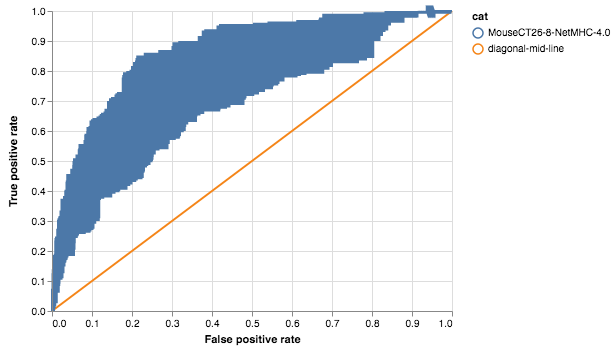

In [26]:
chart = alt.Chart(df_roc).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_line().encode(
    x=alt.X('fpr', title='False positive rate'),
    y=alt.Y('tpr', title='True positive rate'),
    color='cat:N'
)

chart

In [50]:
df_metrics3 = df_metrics
df_roc3 = df_roc

In [51]:
df_metrics3

,Dataset,peptideLength,NetMHCVersion,Combination,metric,value
0,HumanPBMCs,8,NetMHC-4.0,ANN_score-mean_log_tpm-minBS,AUC,0.722897
1,HumanPBMCs,8,NetMHC-4.0,ANN_score-mean_log_tpm-minBS,Accuracy,0.596247
2,HumanPBMCs,8,NetMHC-4.0,ANN_score-mean_log_tpm-minBS,posAcc,0.573840
3,HumanPBMCs,8,NetMHC-4.0,ANN_score-mean_log_tpm-minBS,negAcc,0.583037
4,HumanPBMCs,8,NetMHC-4.0,ANN_score-minBS,AUC,0.625144
5,HumanPBMCs,8,NetMHC-4.0,ANN_score-minBS,Accuracy,0.583007
6,HumanPBMCs,8,NetMHC-4.0,ANN_score-minBS,posAcc,0.573840
7,HumanPBMCs,8,NetMHC-4.0,ANN_score-minBS,negAcc,0.583037
8,HumanPBMCs,8,NetMHC-4.0,ANN_score-mean_log_tpm,AUC,0.716445
9,HumanPBMCs,8,NetMHC-4.0,ANN_score-mean_log_tpm,Accuracy,0.611028


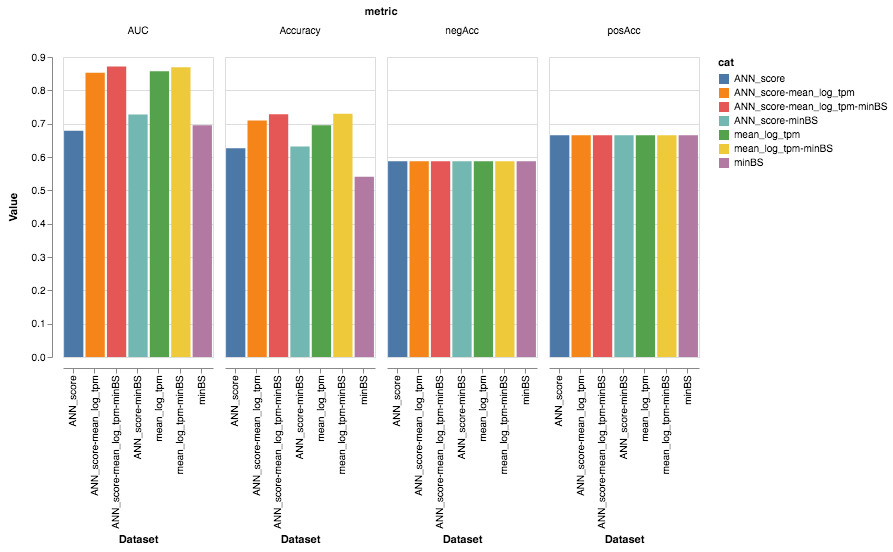

In [27]:
chart = alt.Chart(df_metrics).transform_calculate(
    cat = "datum.Combination"
).mark_bar().encode(
    x=alt.X('cat:N', title='Dataset'),
    y=alt.Y('value', title='Value'),
    color='cat:N',
    column='metric:N'
)

chart.properties(width=150)

## Heavy lifting

In [39]:
def apply_dataset(dataset, peplen, netmhc_v,):
    f = 'finalTables/{}_{}_{}.tsv.gz'.format(dataset, peplen, netmhc_v)
    df = pd.read_csv(f, sep = '\t', index_col=0)
    
    # Remove non-source peptides detected in source transcripts
    df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
    
    fpr, tpr, thresholds = metrics.roc_curve(df.peptide_detected, df.ANN_score)
    auc = metrics.auc(fpr, tpr)
    
    pos_acc = sum((df.peptide_detected == True) & (df.ANN_score > 0.5)) / sum(df.peptide_detected == True)
    neg_acc = sum((df.peptide_detected == False) & (df.ANN_score <= 0.5)) / sum(df.peptide_detected == False)
    
    global df_metrics
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, 'posAcc', pos_acc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, 'negAcc', neg_acc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, 'AUC', auc]

    seen = set()
    reduced = [x for x in zip(np.round(fpr, 3), np.round(tpr, 3)) if x not in seen and not seen.add(x)]
    df_r = pd.DataFrame(reduced, columns=['fpr', 'tpr'])
    df_r['Dataset'] = dataset
    df_r['peptideLength'] = peplen
    df_r['NetMHCVersion'] = netmhc_v
    
    global df_roc
    df_roc = pd.concat([df_roc, df_r], sort=False)
    
#     precision, recall, thresholds = metrics.precision_recall_curve(df.peptide_detected, df.ANN_score)
#     seen = set()
#     reduced = [x for x in zip(np.round(precision, 3), np.round(recall, 3)) if x not in seen and not seen.add(x)]
#     df_r = pd.DataFrame(reduced, columns=['precision', 'recall'])
#     df_r['Dataset'] = dataset
#     df_r['NetMHCVersion'] = netmhc_v
#     global df_pr
#     df_pr = pd.concat([df_pr, df_r], sort=False)
    
    return df[df.peptide_detected == True].ANN_score, df[df.peptide_detected == False].ANN_score

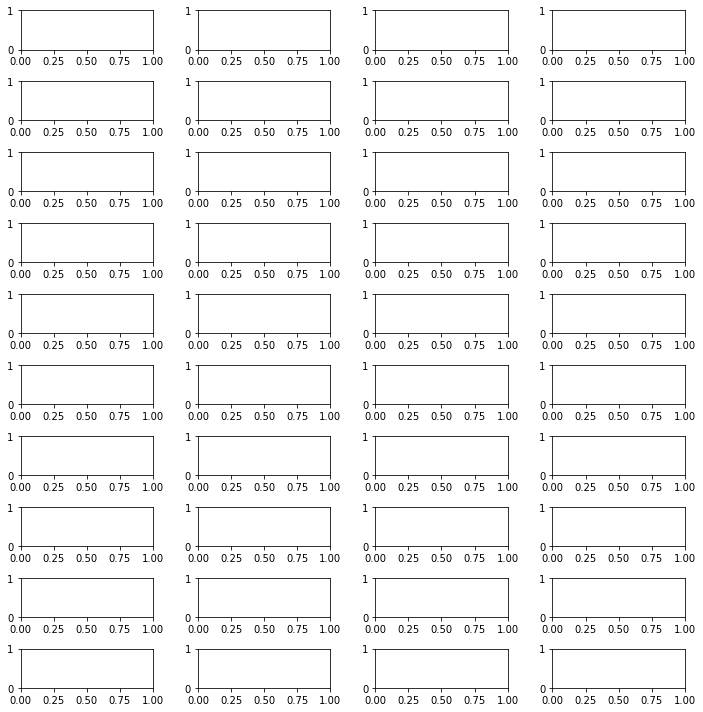

In [44]:
df_metrics = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'metric', 'value'])

df_roc = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'fpr', 'tpr'])
df_roc.loc[0] = ['diagonal', 'mid', 'line', 0, 0]
df_roc.loc[1] = ['diagonal', 'mid', 'line', 1, 1]

df_pr = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'precision', 'recall'])

datasets = ['HumanPBMCs']
peplens = ['8', '9', '10', '11']
netmhc_vs = ['NetMHC-4.0']#, 'NetMHCpan-4.0a']

fix, axs = plt.subplots(len(datasets)*len(netmhc_v), len(peplens), figsize=(10,10))
plt.tight_layout()
for i, d in enumerate(datasets):
    for j, l in enumerate(peplens):
        for k, v in enumerate(netmhc_vs):
            s, ns = apply_dataset(d, l, v)
            #sns.distplot(s, ax=axs[i+k][j])
            #sns.distplot(ns, ax=axs[i+k][j])

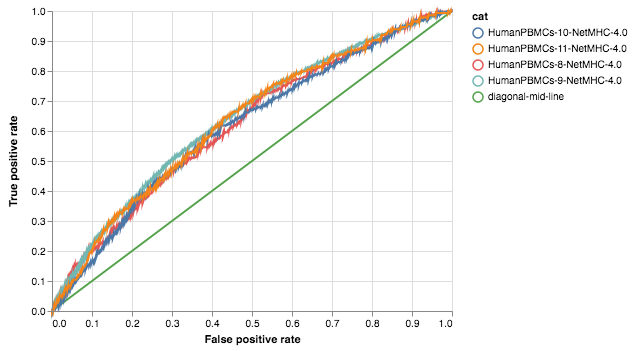

In [45]:
chart = alt.Chart(df_roc).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_line().encode(
    x=alt.X('fpr', title='False positive rate'),
    y=alt.Y('tpr', title='True positive rate'),
    color='cat:N'
)

chart

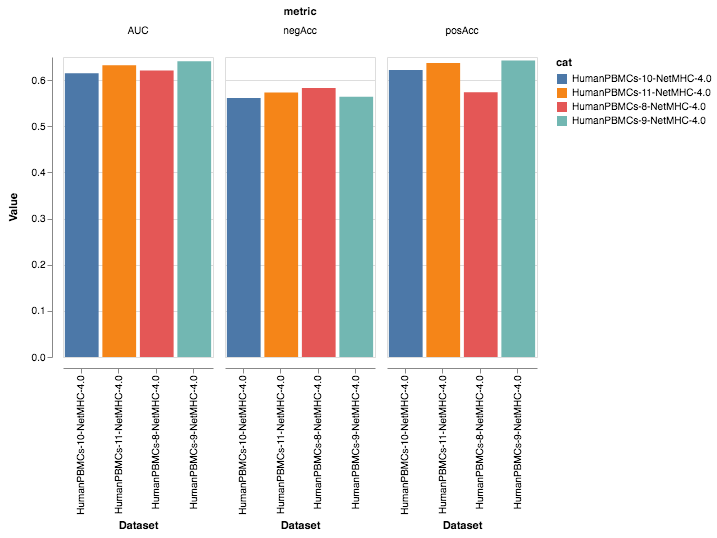

In [46]:
chart = alt.Chart(df_metrics).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_bar().encode(
    x=alt.X('cat:N', title='Dataset'),
    y=alt.Y('value', title='Value'),
    color='cat:N',
    column='metric:N'
)

chart.properties(width=150)

In [24]:
# chart = alt.Chart(df_pr).transform_calculate(
#     cat="datum.Dataset + '-' + datum.NetMHCVersion"
# ).mark_line().encode(
#     x=alt.X('recall', title='Recall'),
#     y=alt.Y('precision', title='Precision'),
#     color='cat:N'
# )

# chart

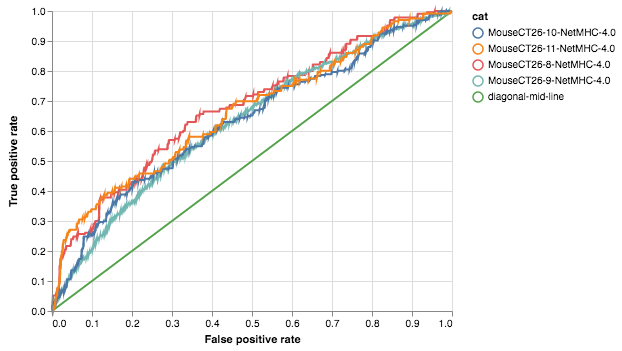

In [41]:
chart = alt.Chart(df_roc).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_line().encode(
    x=alt.X('fpr', title='False positive rate'),
    y=alt.Y('tpr', title='True positive rate'),
    color='cat:N'
)

chart

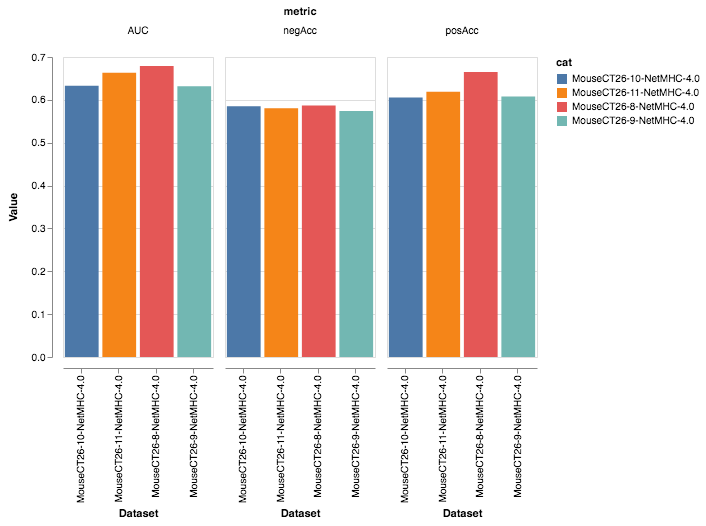

In [42]:
chart = alt.Chart(df_metrics).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_bar().encode(
    x=alt.X('cat:N', title='Dataset'),
    y=alt.Y('value', title='Value'),
    color='cat:N',
    column='metric:N'
)

chart.properties(width=150)